In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("kc_house_data.csv")

train_ratio = 0.8
test_ratio = 0.2
shuffled_df = df.sample(frac=1, random_state=42).reset_index(drop=True)
split_index = int(len(shuffled_df) * train_ratio)

train_df = shuffled_df[:split_index]
test_df = shuffled_df[split_index:]

features = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "condition", "grade", "sqft_above", "sqft_basement", "yr_built", "yr_renovated", "zipcode", "sqft_living15", "sqft_lot15"]

X_train = train_df[features].values
y_train = train_df["price"].values
X_test = test_df[features].values
y_test = test_df["price"].values

In [ ]:
def linear_regression(X, y, learning_rate=0.01, epochs=1000):
    X = np.array(X, dtype=float)
    y = np.array(y, dtype=float)
    X_mean = np.mean(X, axis=0)
    X_std = np.std(X, axis=0)
    X_scaled = (X - X_mean) / (X_std + 1e-8)

    n_samples, n_features = X_scaled.shape
    m = np.zeros(n_features)
    c = 0.0
    loss_history = []

    for epoch in range(epochs):
        y_pred = np.dot(X_scaled, m) + c

        dm = (-2 / n_samples) * np.dot(X_scaled.T, (y - y_pred))
        dc = (-2 / n_samples) * np.sum(y - y_pred)

        m = m - (learning_rate * dm)
        c = c - (learning_rate * dc)

        loss = np.mean((y - y_pred) ** 2)
        loss_history.append(loss)
        if epoch % 100 == 0:
            print(f"Epoch {epoch} | Loss: {loss:.2f}")

    final_loss = np.mean((y - (np.dot(X_scaled, m) + c)) ** 2)

    print(f"Final Loss: {final_loss:.2f}")

    return m, c, loss_history, X_mean, X_std

In [24]:
m, c, loss_history, X_mean, X_std = linear_regression(X_train, y_train, learning_rate=0.01, epochs=1000)

Epoch 0 | Loss: 431758258800.00
Epoch 100 | Loss: 60262383351.18
Epoch 200 | Loss: 53657269055.78
Epoch 300 | Loss: 53226749704.68
Epoch 400 | Loss: 53117448443.22
Epoch 500 | Loss: 53079542395.99
Epoch 600 | Loss: 53065618722.34
Epoch 700 | Loss: 53060359205.82
Epoch 800 | Loss: 53058331990.36
Epoch 900 | Loss: 53057538210.70
Final Loss: 53057223410.68


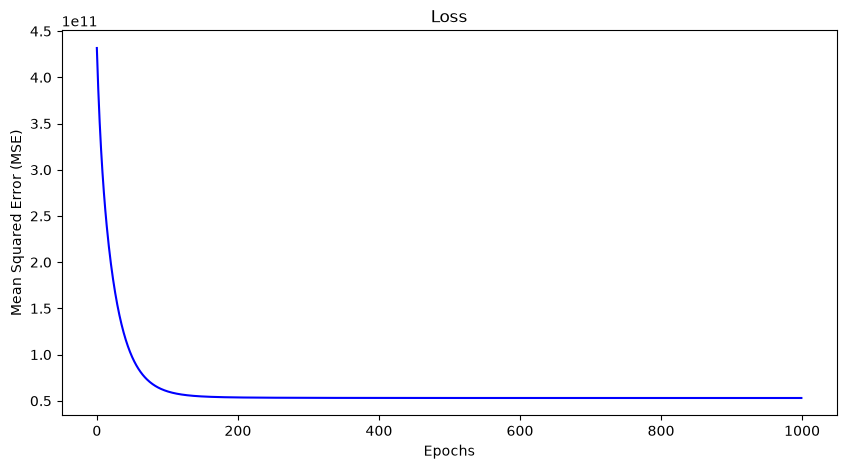

In [25]:
plt.figure(figsize=(10, 5))
plt.plot(loss_history, color='blue')
plt.title("Loss")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error (MSE)")
plt.show()

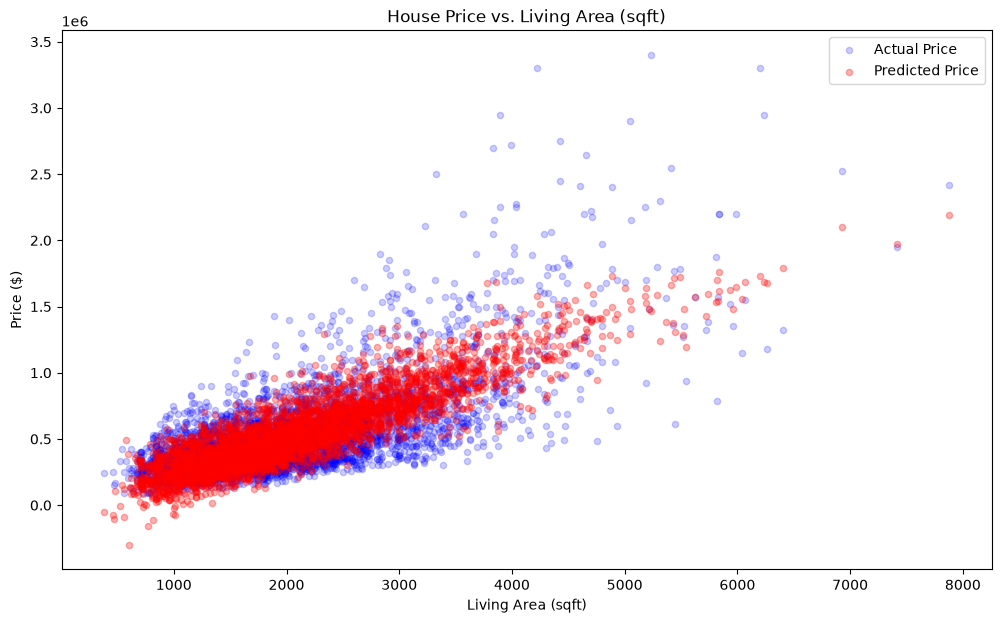

In [ ]:
X_test_scaled = (X_test - X_mean) / (X_std + 1e-8)
pred_values = np.dot(X_test_scaled, m) + c

sqft_living_test = X_test[:, 2] 

plt.figure(figsize=(12, 7))

plt.scatter(sqft_living_test, y_test, color='blue', alpha=0.2, label="Actual Price", s=20)

plt.scatter(sqft_living_test, pred_values, color='red', alpha=0.3, label="Predicted Price", s=20)

plt.title("House Price vs. Living Area (sqft)")
plt.xlabel("Living Area (sqft)")
plt.ylabel("Price ($)")

plt.legend()
plt.show()